# Tema 13 · Modelos de Clasificación — Guía 4: Eventos Raros en Bolsa: Alertas de Caída Extrema, Desbalance y Costos
**Curso:** Minería de Datos en Python (DM) · FISI · UNMSM · 2026-II · **Laboratorio 12 · Guía 4** · Docente: Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Objetivo:** construir una **alerta de caída extrema** (el activo pierde **4 % o más** desde hoy en algún cierre de las próximas 10 sesiones) y tratar el **desbalance** con pesos, **SMOTE** (dentro del pipeline) y **umbral por costos**. Es el análogo bursátil de la detección de fraude o de robo de electricidad del sílabo: pocos positivos, errores asimétricos.

**Datos:** Yahoo Finance (28 activos, hasta el 19-nov-2026) con respaldo en CSV. **Nada de este material es asesoría de inversión.**

# 1. Importación de librerías y carga de datos

In [1]:
# Librerías del laboratorio
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")
SEMILLA = 2026  # semilla global: reproducibilidad
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"}
)

In [2]:
# Librerías de esta guía (imbalanced-learn aporta SMOTE y un Pipeline que remuestrea solo el entrenamiento)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineIB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    TimeSeriesSplit,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.datasets import make_classification
from sklearn.calibration import calibration_curve

In [3]:
# Precios ajustados de 28 activos hasta el cierre del 19-nov-2026. Si los 4 CSV del curso (carpeta D03) están junto al notebook se usan
# (las cifras coinciden con las de la guía); si no, se descargan de Yahoo Finance (pueden variar en centésimas si Yahoo revisó precios)
import os

TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = {
    "cierres": "26.11.20.cierres_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "altos": "26.11.20.altos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "bajos": "26.11.20.bajos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "volumenes": "26.11.20.volumenes_28_activos_2010-01-04_2026-11-19.csv",
}
if all(os.path.exists(f) for f in ARCH.values()):
    cierres, altos, bajos, volumenes = [
        pd.read_csv(ARCH[k], index_col=0, parse_dates=True)
        for k in ["cierres", "altos", "bajos", "volumenes"]
    ]
    print("Se usó la foto de datos del curso (CSV)")
else:
    try:
        d = yf.download(
            TICKERS,
            start="2010-01-01",
            end="2026-11-20",
            auto_adjust=True,
            progress=False,
        )
        cierres, altos, bajos, volumenes = [
            d[c].reindex(columns=TICKERS) for c in ["Close", "High", "Low", "Volume"]
        ]
        print("Se descargó de Yahoo Finance")
    except Exception as e:
        raise SystemExit(
            "Falló la descarga de Yahoo Finance (%s): suba los 4 CSV del curso junto "
            "al notebook"
            % e
        )
for t in (cierres, altos, bajos, volumenes):
    t.index = pd.to_datetime(t.index)
print(
    "Dimensiones:",
    cierres.shape,
    "| desde",
    cierres.index.min().date(),
    "hasta",
    cierres.index.max().date(),
)
print(
    "Último cierre de SPY:",
    round(float(cierres["SPY"].dropna().iloc[-1]), 2),
    "| VIX:",
    round(float(cierres["^VIX"].dropna().iloc[-1]), 2),
)

Se usó la foto de datos del curso (CSV)
Dimensiones: (4249, 28) | desde 2010-01-04 hasta 2026-11-19
Último cierre de SPY: 715.87 | VIX: 28.44


# 2. Parte I — Laboratorio de contraste sintético (Mundo 2): SMOTE antes o después de dividir
**Fenómeno F5.** SMOTE fabrica positivos nuevos **interpolando** entre vecinos. Si se aplica **antes** de dividir, algunas copias sintéticas caen en validación y sus «vecinos» reales en entrenamiento: la métrica se **infla**. Debe aplicarse **dentro** de cada partición de entrenamiento.

Tasa base del evento: 0.0302
AUC con SMOTE ANTES de dividir (fuga): 0.998 | AUC con SMOTE dentro del pipeline: 0.733 | AUC sin remuestreo: 0.708


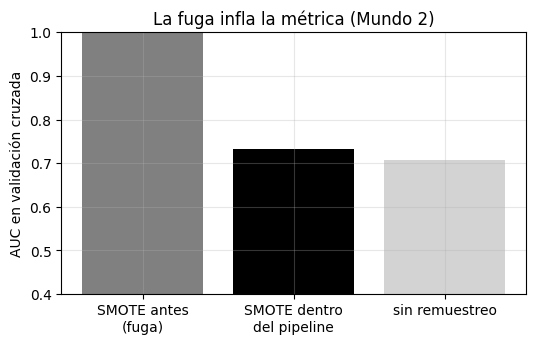

In [4]:
# Evento raro sintético (2 %) con señal débil: SMOTE mal puesto (antes de dividir) frente a SMOTE bien puesto (dentro del pipeline)
Xs, ys = make_classification(
    n_samples=6000,
    n_features=12,
    n_informative=3,
    n_redundant=0,
    weights=[0.98, 0.02],
    class_sep=0.6,
    flip_y=0.02,
    random_state=SEMILLA,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1
)
# MAL: remuestrear todo y luego validar
Xr_mal, yr_mal = SMOTE(random_state=SEMILLA).fit_resample(Xs, ys)
auc_mal = cross_val_score(rf, Xr_mal, yr_mal, cv=cv, scoring="roc_auc").mean()
# BIEN: SMOTE dentro del pipeline (solo remuestrea el entrenamiento de cada pliegue)
bien = PipelineIB([("smote", SMOTE(random_state=SEMILLA)), ("rf", rf)])
auc_bien = cross_val_score(bien, Xs, ys, cv=cv, scoring="roc_auc").mean()
sin = cross_val_score(rf, Xs, ys, cv=cv, scoring="roc_auc").mean()
print("Tasa base del evento:", round(ys.mean(), 4))
print(
    "AUC con SMOTE ANTES de dividir (fuga):",
    round(auc_mal, 3),
    "| AUC con SMOTE dentro del pipeline:",
    round(auc_bien, 3),
    "| AUC sin remuestreo:",
    round(sin, 3),
)
plt.figure(figsize=(6, 3.4))
plt.bar(
    ["SMOTE antes\n(fuga)", "SMOTE dentro\ndel pipeline", "sin remuestreo"],
    [auc_mal, auc_bien, sin],
    color=["gray", "black", "lightgray"],
)
plt.ylim(0.4, 1)
plt.ylabel("AUC en validación cruzada")
plt.title("La fuga infla la métrica (Mundo 2)")
plt.show()

# 3. Datos de SPY: variables causales y objetivos
Partición cronológica 70 % / 30 % con embargo de 22 filas. El evento es `crash`: caída de 4 % o más en algún cierre de las próximas 10 sesiones.

In [5]:
# Variables causales de un activo: solo información conocida al cierre del día t
TICKER = "SPY"
cierre = cierres[TICKER].dropna()
alto, bajo, volumen = (
    altos[TICKER].reindex(cierre.index),
    bajos[TICKER].reindex(cierre.index),
    volumenes[TICKER].reindex(cierre.index),
)
vix = cierres["^VIX"].reindex(cierre.index).ffill()
r = np.log(cierre).diff() * 100  # retorno logarítmico diario en %
X = pd.DataFrame(
    {
        "ret_1": r,
        "ret_5": r.rolling(5).sum(),
        "ret_22": r.rolling(22).sum(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(5),
        "parkinson": (np.log(alto / bajo) / np.sqrt(4 * np.log(2)) * 100)
        .rolling(5)
        .mean(),
        "dist_sma50": (cierre / cierre.rolling(50).mean() - 1) * 100,
        "rango_22": (cierre - bajo.rolling(22).min())
        / (alto.rolling(22).max() - bajo.rolling(22).min()),
        "d_volumen": np.log(volumen / volumen.rolling(22).mean()),
    }
).loc["2012-01-01":]
VARS = list(X.columns)
print(TICKER, "| variables:", VARS)

SPY | variables: ['ret_1', 'ret_5', 'ret_22', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix', 'parkinson', 'dist_sma50', 'rango_22', 'd_volumen']


In [6]:
# Tres objetivos binarios del mismo activo (todos miran al FUTURO; las variables solo al pasado)
y_dir5 = (cierre.shift(-5) / cierre > 1).astype(
    float
)  # ¿cierra más alto dentro de 5 sesiones?
vol_fut = r.shift(-22).rolling(22).std()  # volatilidad de las próximas 22 sesiones
caida = pd.concat([cierre.shift(-k) / cierre - 1 for k in range(1, 11)], axis=1).min(
    axis=1
)  # peor caída en las próximas 10 sesiones
datos = (
    X.join(y_dir5.rename("dir5"))
    .join(vol_fut.rename("vol_fut"))
    .join(caida.rename("caida"))
    .dropna()
)
corte = int(len(datos) * 0.7)
H = 22  # embargo = horizonte más largo
ent, pru = datos.iloc[: corte - H], datos.iloc[corte:]
umbral_vol = ent["vol_fut"].quantile(0.70)  # el umbral sale SOLO del entrenamiento
for t in (ent, pru):
    t["alta_vol"] = (t["vol_fut"] > umbral_vol).astype(int)
    t["crash"] = (t["caida"] <= -0.04).astype(int)
    t["dir5"] = t["dir5"].astype(int)
print(
    "Entrenamiento:",
    len(ent),
    "filas, hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "filas, desde",
    pru.index.min().date(),
)
for obj in ["dir5", "alta_vol", "crash"]:
    print(
        f"{obj:9s} tasa base entrenamiento {ent[obj].mean():.3f} | prueba "
        f"{pru[obj].mean():.3f}"
    )

Entrenamiento: 2582 filas, hasta 2022-04-05 | Prueba: 1117 filas, desde 2022-05-09
dir5      tasa base entrenamiento 0.624 | prueba 0.601
alta_vol  tasa base entrenamiento 0.300 | prueba 0.353
crash     tasa base entrenamiento 0.088 | prueba 0.103


# 4. Parte II — La alerta de caída extrema de SPY (Mundo 3, evento raro)
Cinco estrategias: la logística sin ajustar, con **pesos por clase**, con **SMOTE dentro del pipeline** y dos ensambles. Con una tasa base cercana al 10 %, la **exactitud** engaña; se lee **AUC-PR** frente a la tasa base.

In [7]:
# Estrategias frente al desbalance (todas entrenadas solo con el entrenamiento; la prueba se mira una vez)
modelos = {
    "Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Logística con pesos": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
    ),
    "Logística + SMOTE": PipelineIB(
        [
            ("sc", StandardScaler()),
            ("smote", SMOTE(random_state=SEMILLA)),
            ("lr", LogisticRegression(max_iter=2000)),
        ]
    ),
    "Random Forest con pesos": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=30,
        class_weight="balanced_subsample",
        random_state=SEMILLA,
        n_jobs=-1,
    ),
}
filas, probs = [], {}
for nombre, m in modelos.items():
    m.fit(ent[VARS], ent["crash"])
    p = m.predict_proba(pru[VARS])[:, 1]
    probs[nombre] = p
    y_hat = (p >= 0.5).astype(int)
    filas.append(
        [
            nombre,
            accuracy_score(pru["crash"], y_hat),
            precision_score(pru["crash"], y_hat, zero_division=0),
            recall_score(pru["crash"], y_hat),
            f1_score(pru["crash"], y_hat),
            roc_auc_score(pru["crash"], p),
            average_precision_score(pru["crash"], p),
        ]
    )
tabla = pd.DataFrame(
    filas,
    columns=[
        "modelo",
        "exactitud",
        "precisión",
        "exhaustividad",
        "F1",
        "AUC-ROC",
        "AUC-PR",
    ],
)
print(
    "Tasa base de caída extrema en la prueba:",
    round(pru["crash"].mean(), 3),
    "| exactitud de «nunca hay caída»:",
    round(1 - pru["crash"].mean(), 3),
)
print(tabla.round(3).to_string(index=False))

Tasa base de caída extrema en la prueba: 0.103 | exactitud de «nunca hay caída»: 0.897
                 modelo  exactitud  precisión  exhaustividad    F1  AUC-ROC  AUC-PR
              Logística      0.893      0.167          0.009 0.017    0.690   0.188
    Logística con pesos      0.621      0.167          0.670 0.267    0.689   0.192
      Logística + SMOTE      0.620      0.172          0.704 0.276    0.689   0.193
Random Forest con pesos      0.731      0.198          0.530 0.288    0.707   0.186


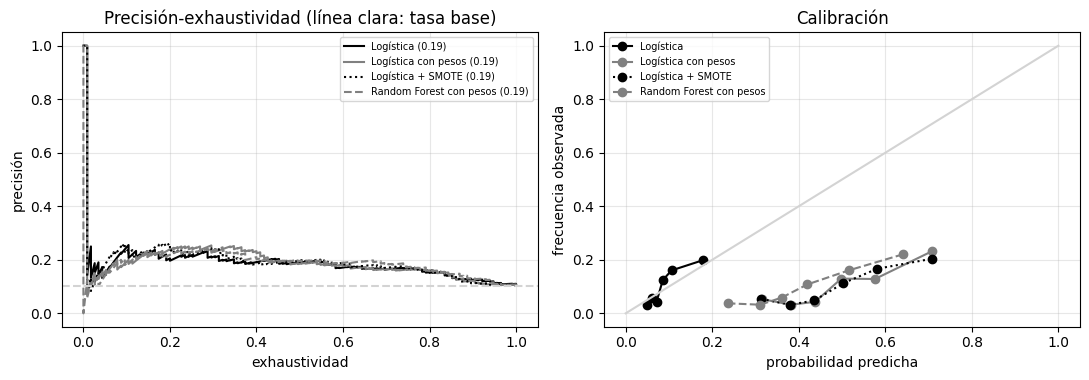

In [8]:
# Curva precisión-exhaustividad frente a la tasa base, y calibración
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
estilos = {
    "Logística": ("black", "-"),
    "Logística con pesos": ("gray", "-"),
    "Logística + SMOTE": ("black", ":"),
    "Random Forest con pesos": ("gray", "--"),
}
for nombre, p in probs.items():
    c, ls = estilos[nombre]
    pr, rc, _ = precision_recall_curve(pru["crash"], p)
    ax[0].plot(
        rc,
        pr,
        color=c,
        ls=ls,
        label=f"{nombre} ({average_precision_score(pru['crash'], p):.2f})",
    )
    fr, mp = calibration_curve(pru["crash"], p, n_bins=6, strategy="quantile")
    ax[1].plot(mp, fr, "o-", color=c, ls=ls, label=nombre)
ax[0].axhline(pru["crash"].mean(), ls="--", color="lightgray")
ax[0].set_title("Precisión-exhaustividad (línea clara: tasa base)")
ax[0].set_xlabel("exhaustividad")
ax[0].set_ylabel("precisión")
ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], color="lightgray")
ax[1].set_title("Calibración")
ax[1].set_xlabel("probabilidad predicha")
ax[1].set_ylabel("frecuencia observada")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

# 5. Parte III — El umbral por costos (la decisión de negocio)
Si **no avisar** antes de una caída cuesta 10 unidades (la pérdida evitable al cubrir) y **avisar en falso** cuesta 1 (el costo de cubrir y de perder rebote), el umbral teórico es 1/(1 + 10) ≈ 0,09. El umbral se **elige en validación** (el tramo final del entrenamiento) y se evalúa una vez en la prueba.

                   regla  avisos  exhaustividad  precisión  costo_total
            Nunca avisar       0          0.000      0.000       1150.0
          Siempre avisar    1117          1.000      0.103       1002.0
             Umbral 0.50       4          0.000      0.000       1154.0
Umbral por costos (0.07)     594          0.713      0.138        842.0


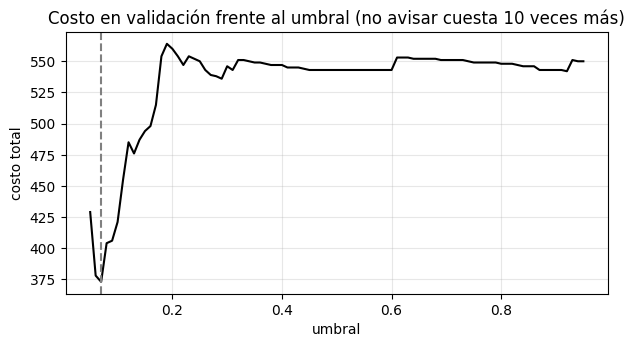

In [9]:
# Umbral por costos: elegido en validación cronológica, evaluado en la prueba
c_fp, c_fn = 1.0, 10.0
corte_v = int(len(ent) * 0.8)
ent2, val = ent.iloc[: corte_v - H], ent.iloc[corte_v:]
m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent2[VARS], ent2["crash"]
)  # sin pesos: probabilidades calibradas
p_val = m.predict_proba(val[VARS])[:, 1]
us = np.linspace(0.05, 0.95, 91)
costo_val = [
    c_fp * ((p_val >= u) & (val["crash"] == 0)).sum()
    + c_fn * ((p_val < u) & (val["crash"] == 1)).sum()
    for u in us
]
u_opt = us[int(np.argmin(costo_val))]
p_pru = m.predict_proba(pru[VARS])[:, 1]
filas = []
for nombre, u in [
    ("Nunca avisar", 2.0),
    ("Siempre avisar", -1.0),
    ("Umbral 0.50", 0.5),
    (f"Umbral por costos ({u_opt:.2f})", u_opt),
]:
    y_hat = (p_pru >= u).astype(int)
    costo = (
        c_fp * ((y_hat == 1) & (pru["crash"] == 0)).sum()
        + c_fn * ((y_hat == 0) & (pru["crash"] == 1)).sum()
    )
    filas.append(
        [
            nombre,
            int(y_hat.sum()),
            recall_score(pru["crash"], y_hat),
            precision_score(pru["crash"], y_hat, zero_division=0),
            costo,
        ]
    )
print(
    pd.DataFrame(
        filas, columns=["regla", "avisos", "exhaustividad", "precisión", "costo_total"]
    )
    .round(3)
    .to_string(index=False)
)
plt.figure(figsize=(7, 3.4))
plt.plot(us, costo_val, color="black")
plt.axvline(u_opt, ls="--", color="gray")
plt.title("Costo en validación frente al umbral (no avisar cuesta 10 veces más)")
plt.xlabel("umbral")
plt.ylabel("costo total")
plt.show()

# 6. Parte IV — ¿Funciona igual en otros activos? (el portafolio del grupo)
La misma alerta (logística con pesos) sobre seis activos: la tasa base cambia con el activo y el AUC-PR se compara con **su propia tasa base**.

activo  tasa_base_prueba  AUC-ROC  AUC-PR  AUC-PR / tasa base
   SPY             0.110    0.691   0.187               1.691
   QQQ             0.207    0.658   0.288               1.388
  AAPL             0.280    0.580   0.334               1.195
   JPM             0.194    0.568   0.219               1.130
   BVN             0.421    0.520   0.437               1.038
  SCCO             0.431    0.546   0.485               1.126


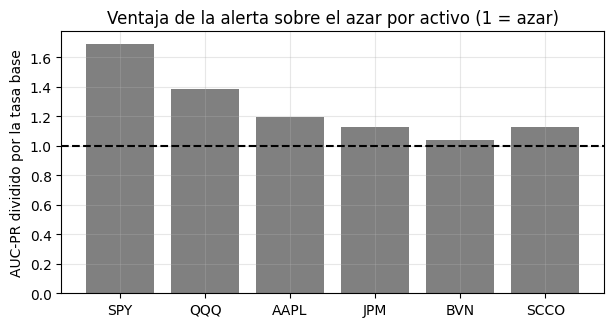

In [10]:
# Misma alerta sobre seis activos: se reconstruyen variables y objetivos con el código de la Parte I
filas = []
for t in ["SPY", "QQQ", "AAPL", "JPM", "BVN", "SCCO"]:
    c = cierres[t].dropna()
    a, b, v = (
        altos[t].reindex(c.index),
        bajos[t].reindex(c.index),
        volumenes[t].reindex(c.index),
    )
    vx = cierres["^VIX"].reindex(c.index).ffill()
    rr = np.log(c).diff() * 100
    Xt = pd.DataFrame(
        {
            "ret_1": rr,
            "ret_5": rr.rolling(5).sum(),
            "ret_22": rr.rolling(22).sum(),
            "vol_5": rr.rolling(5).std(),
            "vol_22": rr.rolling(22).std(),
            "vol_66": rr.rolling(66).std(),
            "vix": vx,
            "d_vix": vx.diff(5),
            "dist_sma50": (c / c.rolling(50).mean() - 1) * 100,
            "rango_22": (c - b.rolling(22).min())
            / (a.rolling(22).max() - b.rolling(22).min()),
        }
    ).loc["2012-01-01":]
    caida_t = pd.concat([c.shift(-k) / c - 1 for k in range(1, 11)], axis=1).min(axis=1)
    dt = (
        Xt.join((caida_t <= -0.04).astype(int).rename("crash"))
        .join(caida_t.rename("caida"))
        .dropna()
    )
    k = int(len(dt) * 0.7)
    et, pt = dt.iloc[: k - H], dt.iloc[k:]
    cols = [x for x in Xt.columns]
    mt = make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
    ).fit(et[cols], et["crash"])
    pp = mt.predict_proba(pt[cols])[:, 1]
    filas.append(
        [
            t,
            pt["crash"].mean(),
            roc_auc_score(pt["crash"], pp),
            average_precision_score(pt["crash"], pp),
            average_precision_score(pt["crash"], pp) / pt["crash"].mean(),
        ]
    )
act = pd.DataFrame(
    filas,
    columns=["activo", "tasa_base_prueba", "AUC-ROC", "AUC-PR", "AUC-PR / tasa base"],
)
print(act.round(3).to_string(index=False))
plt.figure(figsize=(7, 3.4))
plt.bar(act["activo"], act["AUC-PR / tasa base"], color="gray")
plt.axhline(1, ls="--", color="black")
plt.ylabel("AUC-PR dividido por la tasa base")
plt.title("Ventaja de la alerta sobre el azar por activo (1 = azar)")
plt.show()

# 7. Resumen
- Con eventos raros, **nunca avisar** acierta el 90–99 % y no sirve: se lee **AUC-PR frente a la tasa base** y el **costo total**.
- **SMOTE** va **dentro** del pipeline; antes de dividir fabrica una métrica inflada.
- El **umbral** sale del cociente de costos y se elige en **validación**; la prueba se mira una sola vez.